In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

transform = transforms.ToTensor()

train_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_size = int(0.9 * len(train_dataset))
val_size = len(train_dataset) - train_size
train_subset, val_subset = random_split(train_dataset, [train_size, val_size])

train_loader = DataLoader(train_subset, batch_size=128, shuffle=True, pin_memory=True)
val_loader = DataLoader(val_subset, batch_size=128, shuffle=False, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False, pin_memory=True)

/home/olaf/studia/nntp/.venv/lib/python3.13/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


In [2]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 32 * 3, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        return self.net(x)

In [3]:
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * x.size(0)
        total_correct += (logits.argmax(dim=1) == y).sum().item()
        total_samples += x.size(0)

    return total_loss / total_samples, total_correct / total_samples

In [4]:
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        logits = model(x)
        loss = criterion(logits, y)

        total_loss += loss.item() * x.size(0)
        total_correct += (logits.argmax(dim=1) == y).sum().item()
        total_samples += x.size(0)

    return total_loss / total_samples, total_correct / total_samples

# Task 1


In [5]:
model = MLP()
print(model)

print(f'parameters count={sum(p.numel() for p in model.parameters())}')

MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=512, bias=True)
    (2): ReLU()
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Linear(in_features=256, out_features=10, bias=True)
  )
)
parameters count=1707274


### What ```torch.nn.Module``` represents?
It represents neural network modules.
Modules can also contain other Modules, allowing them to be nested in a tree strucutre.
### Why PyTorch automatically tracks parameters inside a module?
This way it is really easy to compute the gradient, we know which parameters are trainable.
### When ```nn.Sequentail``` is convenient?
In situations where multiple layers are created in one pipeline.
### When a custom ```nn.Module``` is preferable?
Given a large neural network or special features, new Module should be incorporated.

# Task 2

In [6]:
import matplotlib.pyplot as plt

In [7]:

def plot_results(history):
  fig, axes = plt.subplots(1, 2, figsize=(14, 5))

  metric_configs = [
    ("loss", "Loss", axes[0]),
    ("accuracy", "Accuracy", axes[1])
  ]

  for metric_key, metric_title, ax in metric_configs:
    for name, values in history.items():
      if metric_key in name:
        ax.plot(
          values,
          marker='o',
          linewidth=2.5,
          markersize=6,
          label=name.title()
        )
    
    ax.set_title(f'{metric_title} over Epochs', fontsize=14, fontweight='bold')
    ax.set_xlabel('Epoch', fontsize=12)
    ax.set_ylabel(metric_title, fontsize=12)
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(frameon=False, fontsize=11)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
  
  fig.suptitle('Training History', fontsize=16, fontweight='bold')
  fig.tight_layout()
  plt.show()

epoch=0
epoch=1
epoch=2
epoch=3
epoch=4
epoch=5
epoch=6
epoch=7
epoch=8
epoch=9
epoch=10
epoch=11
epoch=12
epoch=13
epoch=14
epoch=15
epoch=16
epoch=17
epoch=18
epoch=19


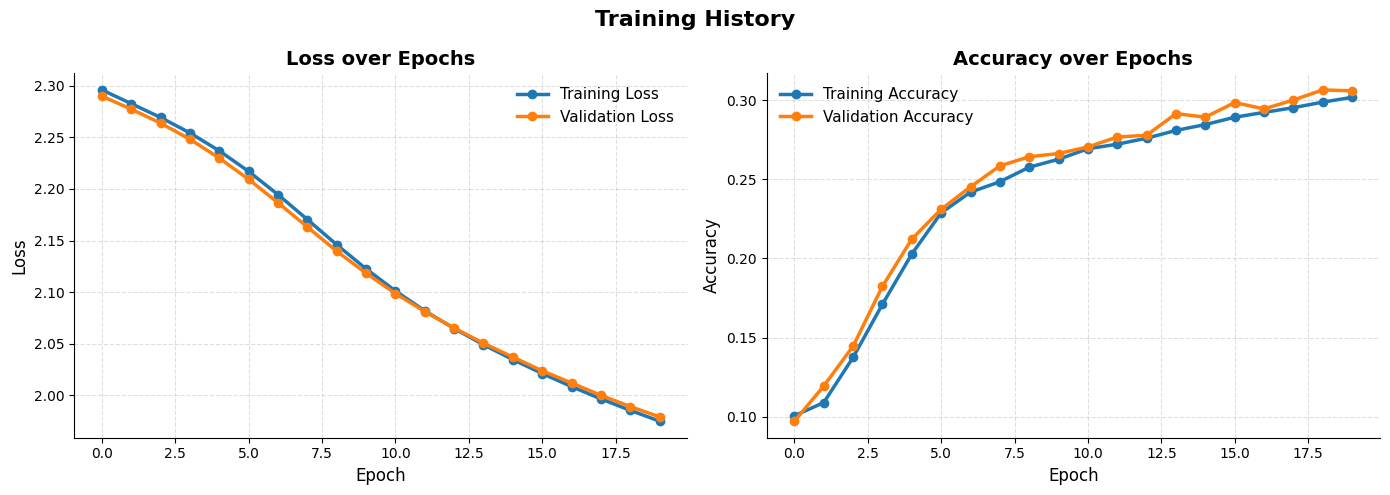

In [8]:
optimizer = torch.optim.SGD(model.parameters())
criterion = torch.nn.CrossEntropyLoss()

history = {
  'training loss': [],
  'validation loss': [],
  'training accuracy': [],
  'validation accuracy': []
}

model = model.to(device)
for epoch in range(20):
  print(f'{epoch=}')
  train_loss, train_acc = train_one_epoch(
    model, train_loader, optimizer, criterion, device
  )
  history['training loss'].append(train_loss)
  history['training accuracy'].append(train_acc)

  valid_loss, valid_acc = evaluate(
    model, val_loader, criterion, device
  )
  history['validation loss'].append(valid_loss)
  history['validation accuracy'].append(valid_acc)

plot_results(history)

### Why we use mini-batches?
Mini-batches help in convergance of stochastic gradient method. Gradient direction is less chaotic.
### What ```model.train()``` and ```model.eval()``` do?
They change the bechavior of computing the gradient. During eval the computations of the gradients are ommited.
### Why gradients are diable during validation?
They are just a computation hassle. They are not needed for evaluation the model.
### Why ```optimizer.zero_grad()``` is necessary?
Pytorch does not zero the gradients in between the epochs so without the ```zero_grad``` gradients would accumulate and destroy the training.

# Task 3

In [9]:
import copy
import pandas as pd


==== SGD $\epsilon=10^{-3}$ ====


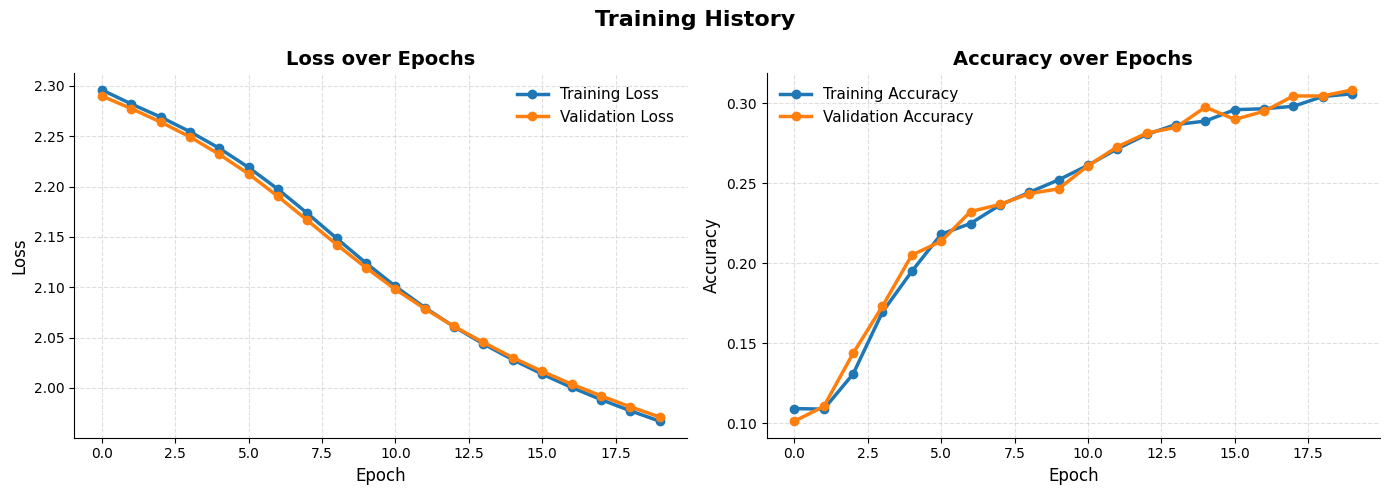


==== SGD $\epsilon=10^{-4}$ ====


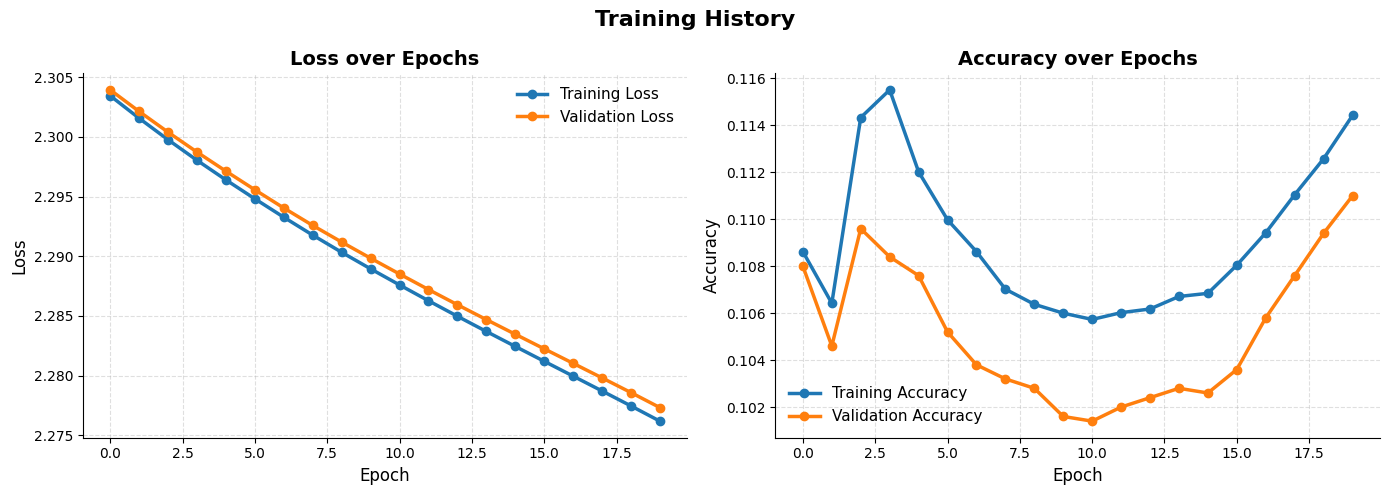


==== SGD + Momentum ====


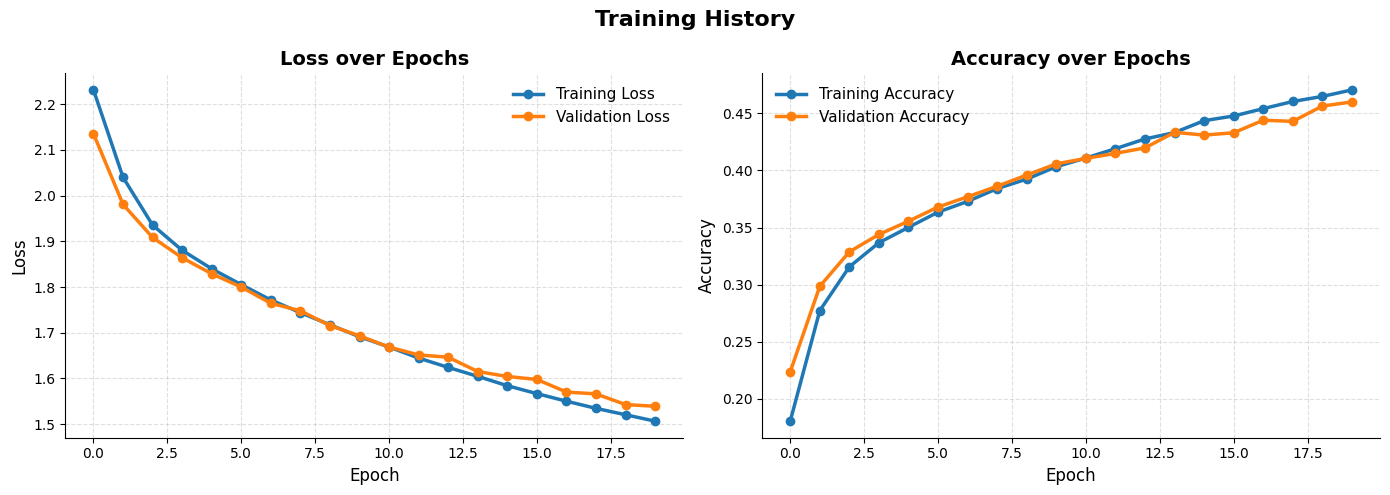


==== SGD + Nesterov ====


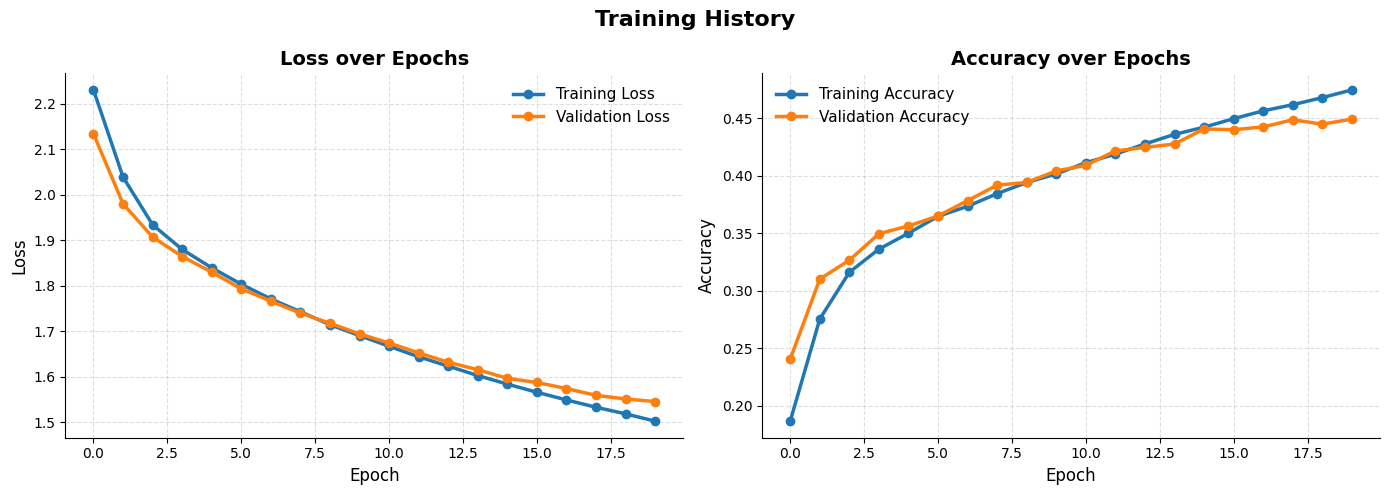


==== RMSprop $\epsilon=10^{-5}$ ====


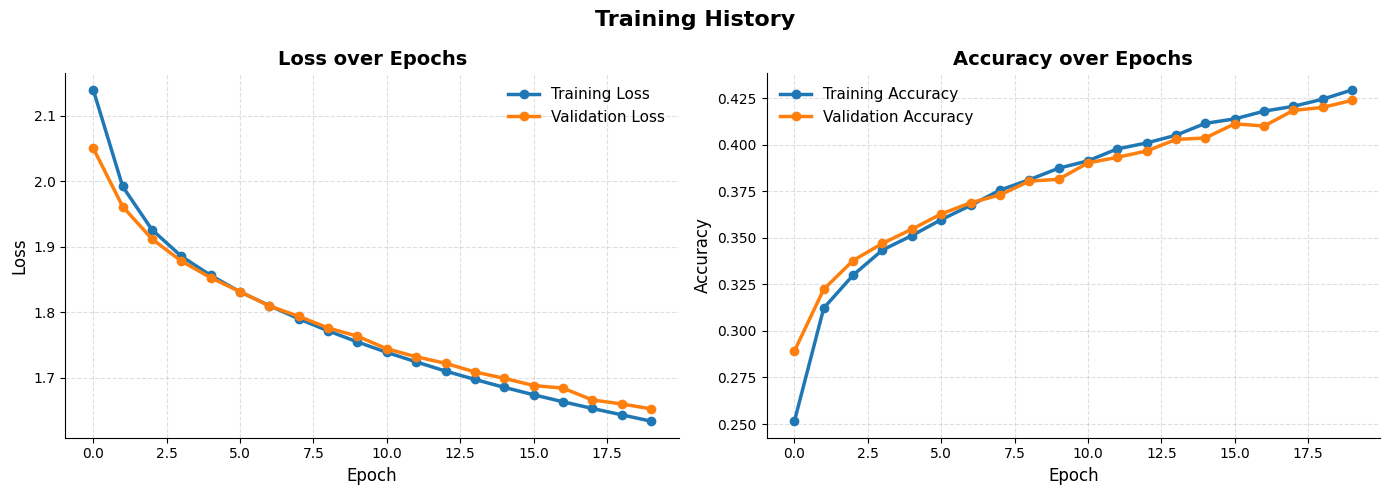


==== RMSprop $\epsilon=10^{-4}$ ====


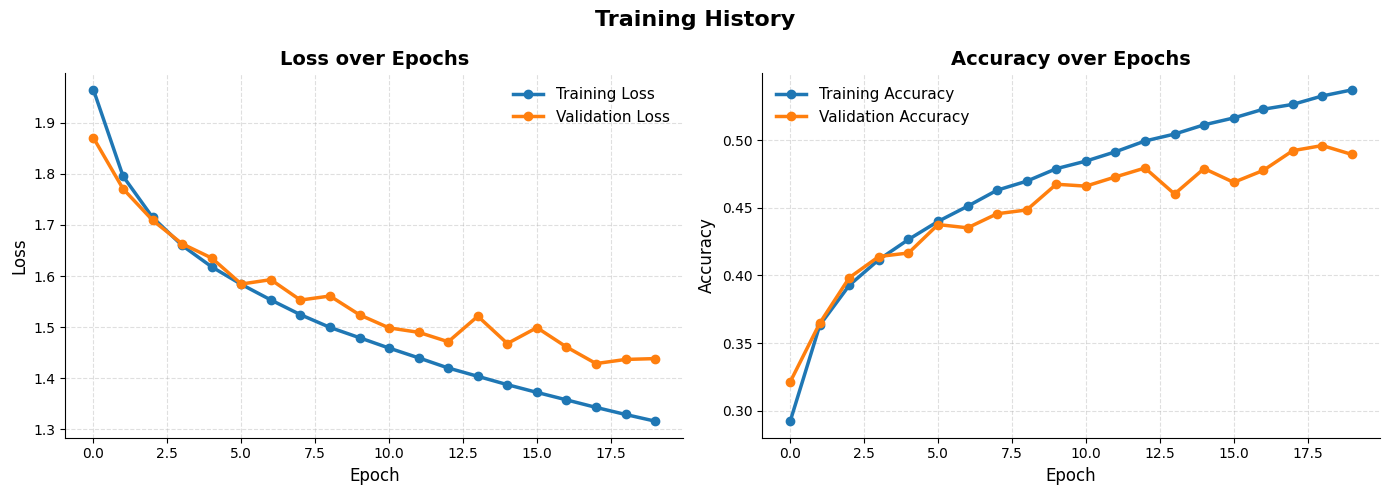


==== RMSprop $\epsilon=10^{-3}$ ====


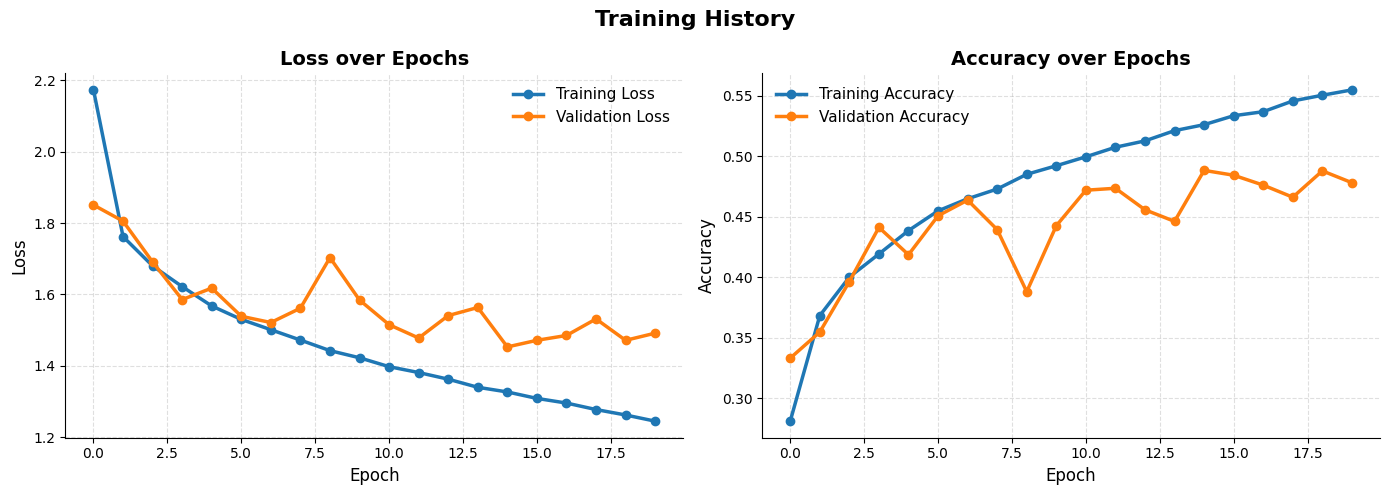


==== Adam $\epsilon=10^{-5}$ ====


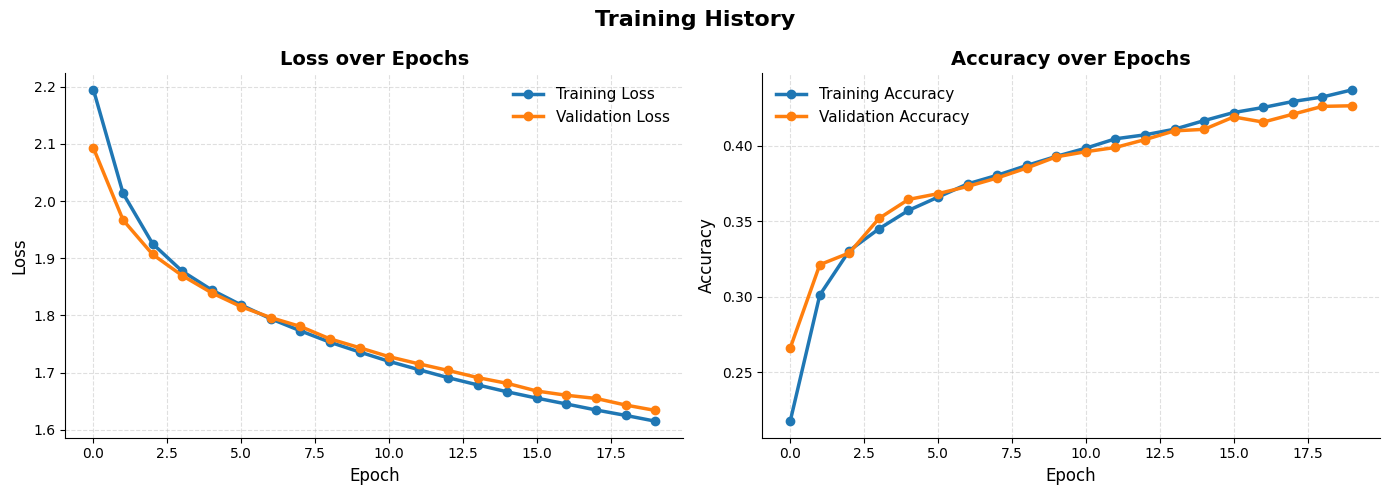


==== Adam $\epsilon=10^{-4}$ ====


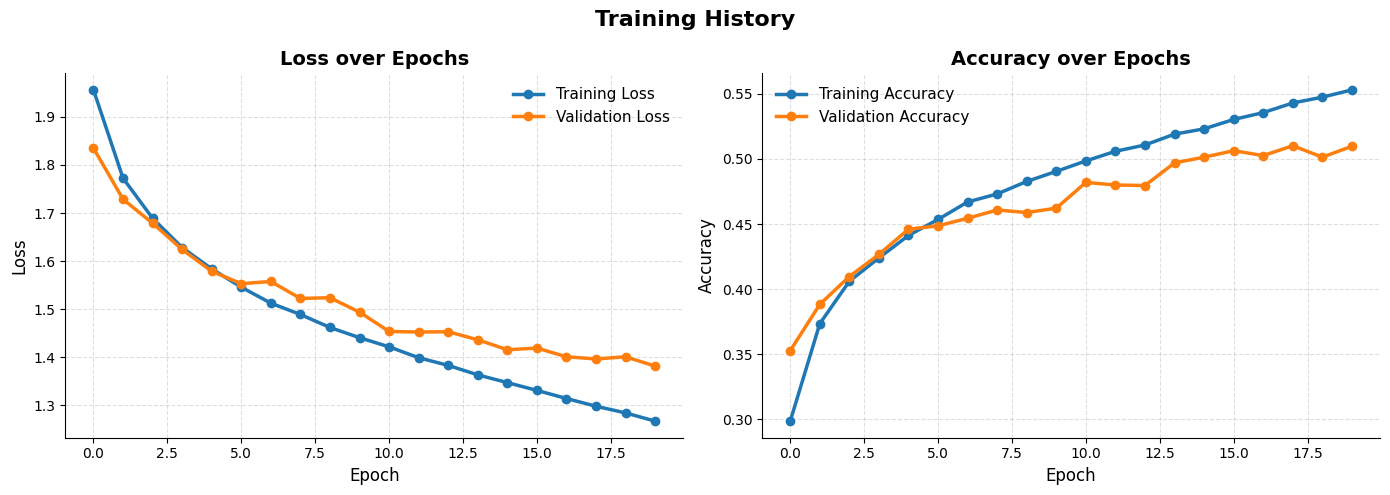


==== Adam $\epsilon=10^{-3}$ ====


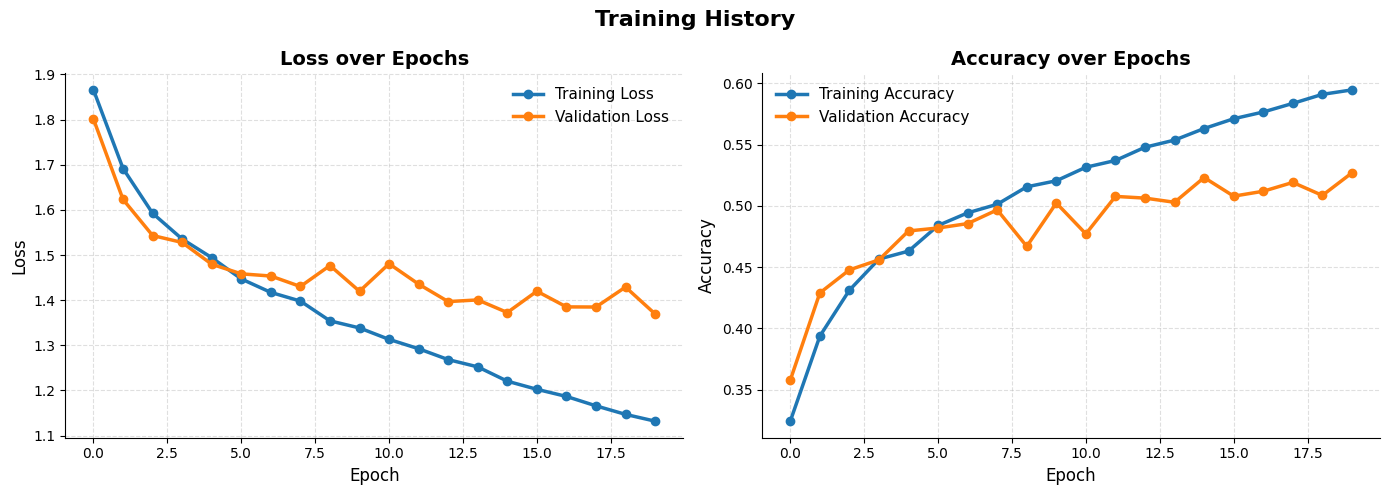

,optimizer name,lr,final train loss,final val loss,final train acc,final val acc
9,Adam $\epsilon=10^{-3}$,0.001000,1.132035,1.369423,0.594756,0.527000
8,Adam $\epsilon=10^{-4}$,0.000100,1.267191,1.381672,0.553133,0.509800
5,RMSprop $\epsilon=10^{-4}$,0.000100,1.316245,1.438630,0.537111,0.489400
6,RMSprop $\epsilon=10^{-3}$,0.001000,1.244933,1.491548,0.555022,0.478200
2,SGD + Momentum,0.001000,1.506428,1.538979,0.470556,0.460000
3,SGD + Nesterov,0.001000,1.502021,1.545174,0.474578,0.449200
7,Adam $\epsilon=10^{-5}$,0.000010,1.614901,1.633712,0.436911,0.426400
4,RMSprop $\epsilon=10^{-5}$,0.000010,1.633719,1.652601,0.429400,0.423800
0,SGD $\epsilon=10^{-3}$,0.001000,1.967010,1.971151,0.305756,0.308200
1,SGD $\epsilon=10^{-4}$,0.000100,2.276174,2.277312,0.114422,0.111000


In [10]:
ref_model = MLP().to(device)

optimizer_configs = {
  r"SGD $\epsilon=10^{-3}$": {"class": torch.optim.SGD, "params": {"lr": 0.001}},
  r"SGD $\epsilon=10^{-4}$": {"class": torch.optim.SGD, "params": {"lr": 0.0001}},
  "SGD + Momentum": {"class": torch.optim.SGD, "params": {"lr": 0.001, "momentum": 0.9}},
  "SGD + Nesterov": {"class": torch.optim.SGD, "params": {"lr": 0.001, "momentum": 0.9, "nesterov": True}},
  r"RMSprop $\epsilon=10^{-5}$": {"class": torch.optim.RMSprop, "params": {"lr": 0.00001}},
  r"RMSprop $\epsilon=10^{-4}$": {"class": torch.optim.RMSprop, "params": {"lr": 0.0001}},
  r"RMSprop $\epsilon=10^{-3}$": {"class": torch.optim.RMSprop, "params": {"lr": 0.001}},
  r"Adam $\epsilon=10^{-5}$": {"class": torch.optim.Adam, "params": {"lr": 0.00001}},
  r"Adam $\epsilon=10^{-4}$": {"class": torch.optim.Adam, "params": {"lr": 0.0001}},
  r"Adam $\epsilon=10^{-3}$": {"class": torch.optim.Adam, "params": {"lr": 0.001}},
}

criterion = torch.nn.CrossEntropyLoss()
results = []

for optimizer_name, config in optimizer_configs.items():
  print(f"\n==== {optimizer_name} ====")

  model = copy.deepcopy(ref_model)

  optimizer = config["class"](model.parameters(), **config["params"])

  history = {
    'training loss': [],
    'validation loss': [],
    'training accuracy': [],
    'validation accuracy': []
  }

  for epoch in range(20):
    train_loss, train_acc = train_one_epoch(
      model, train_loader, optimizer, criterion, device
    )
    history['training loss'].append(train_loss)
    history['training accuracy'].append(train_acc)

    valid_loss, valid_acc = evaluate(
      model, val_loader, criterion, device
    )
    history['validation loss'].append(valid_loss)
    history['validation accuracy'].append(valid_acc)
  
  plot_results(history)

  results.append({
    'optimizer name': optimizer_name,
    # 'history': history,
    'lr': optimizer.param_groups[-1]['lr'],
    'final train loss': history['training loss'][-1],
    'final val loss': history['validation loss'][-1],
    'final train acc': history['training accuracy'][-1],
    'final val acc': history['validation accuracy'][-1]
  })

summary_df = pd.DataFrame(results)
summary_df = summary_df.sort_values(by='final val acc', ascending=False)
display(summary_df.style)

### Which optimizer converged fastest?
TODO
### Which optimizer achieved the best validation result?
TODO
### Whether adaptive methods behaved differently from SGD?
Yes, they are. For example, the RMSprop jump around in the validation testing.
### Whether Momentum / Nesterov improved over plain SGD
Yes they did, but as good as expected.


# Task 4

In [ ]:
import torch.nn.init as init

In [ ]:
def init_model(model, init_name='default', std=1.0):
  for m in model.modules():
    if isinstance(m, nn.Linear):
      if init_name == 'default':
        pass
      elif init_name == 'normal_small':
        init.normal_(m.weight, mean=0.0, std=0.01)
        init.zeros_(m.bias)
      elif init_name == 'normal_big':
        init.normal_(m.weight, mean=0.0, std=1.0)
        init.zeros_(m.bias)
      elif init_name == 'xavier':
        init.xavier_normal_(m.weight)
        init.zeros_(m.bias)
      elif init_name == 'he':
        init.kaiming_normal_(m.weight, nonlinearity='relu')
        init.zeros_(m.bias)
      else:
        assert False

def collect_stats(model, x, y, criterion):
  activation_stats = []
  gradient_stats = []
  hooks = []

  def make_hook(layer_name):
    def hook(module, input, output):
      activation_stats.append({
        'layer': layer_name,
        'act_mean': output.detach().mean().item(),
        'act_var': output.detach().var.item()
      })
    return hook

  for i, layer in enumerate(model.modules()):
    if isinstance(layer, nn.Linear):
      hooks.append(layer.register_forward_hook(make_hook(f'Linear_{i}')))
  
  model.train()
  model.zero_grad()

  out = model(x)
  loss = criterion(out, y)
  loss.backward()
  
  for name, param in model.named_parameters():
    if param.grad is not None and 'weight' in name:
      gradient_stats.append({
        'layer': name,
        'grad_mean': param.grad.mean().item(),
        'grad_var': param.grad.var().item(),
        'grad_norm': param.grad.norm().item()
      })

  for h in hooks:
    h.remove()
  
  return activation_stats, gradient_stats